In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Corrected file path
df = pd.read_csv('/Users/karolinamullokand/Desktop/FINALcsv.csv', engine='python')

In [4]:
print(df[df['offer_type'].isin(['bogo', 'discount'])][['offer_type', 'difficulty', 'reward']].dropna())


       offer_type  difficulty  reward
0        discount        10.0     2.0
1        discount        10.0     2.0
3        discount        10.0     2.0
6        discount        20.0     5.0
7        discount        20.0     5.0
...           ...         ...     ...
272751       bogo         5.0     5.0
272752   discount        10.0     2.0
272754   discount        10.0     2.0
272755   discount        10.0     2.0
272758   discount        10.0     2.0

[126145 rows x 3 columns]


In [5]:
#1. Create a new column with human-readable offer names
offer_name_map = {
    'ae264e3637204a6fb9bb56bc8210ddfd': 'bogo 1',
    '4d5c57ea9a6940dd891ad53e9dbe8da0': 'bogo 2',
    '3f207df678b143eea3cee63160fa8bed': 'informational 1',
    '9b98b8c7a33c4b65b9aebfe6a799e6d9': 'bogo 3',
    '0b1e1539f2cc45b7b9fa7c272da2e1d7': 'discount 1',
    '2298d6c36e964ae4a3e7e9706d1fb8c2': 'discount 2',
    'fafdcd668e3743c1bb461111dcafc2a4': 'discount 3',
    '5a8bc65990b245e5a138643cd4eb9837': 'informational 3',
    'f19421c1d4aa40978ebb69ca19b0e20d': 'bogo 4',
    '2906b810c7d4411798c6938adc9daaa5': 'discount 4',
}

df['offer_name'] = df['offer_id'].map(offer_name_map)

In [6]:
#Formual for avg.rewaard rate


import numpy as np

df['reward_rate'] = np.where(
    df['offer_type'].isin(['discount', 'bogo']) &
    df['reward'].notna() & (df['reward'] != 0) &
    df['difficulty'].notna(),
    df['difficulty'] / df['reward'],
    np.nan
)
unique_vals = df[['offer_type', 'difficulty', 'reward', 'reward_rate']].dropna(subset=['reward_rate']).drop_duplicates()
print(unique_vals)


    offer_type  difficulty  reward  reward_rate
0     discount        10.0     2.0     5.000000
6     discount        20.0     5.0     4.000000
23        bogo         5.0     5.0     1.000000
63        bogo        10.0    10.0     1.000000
245   discount         7.0     3.0     2.333333


In [9]:
!pip install seaborn


zsh:1: command not found: pip


In [11]:
!which python
!pip show seaborn


python not found
zsh:1: command not found: pip


In [13]:
import seaborn as sns


/var/folders/y6/pm513z112vnfw2p1c_mbclx40000gn/T/ipykernel_70879/1588221082.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bar = sns.barplot(data=summary, x='offer_name', y='completions', ax=ax1, palette='viridis')


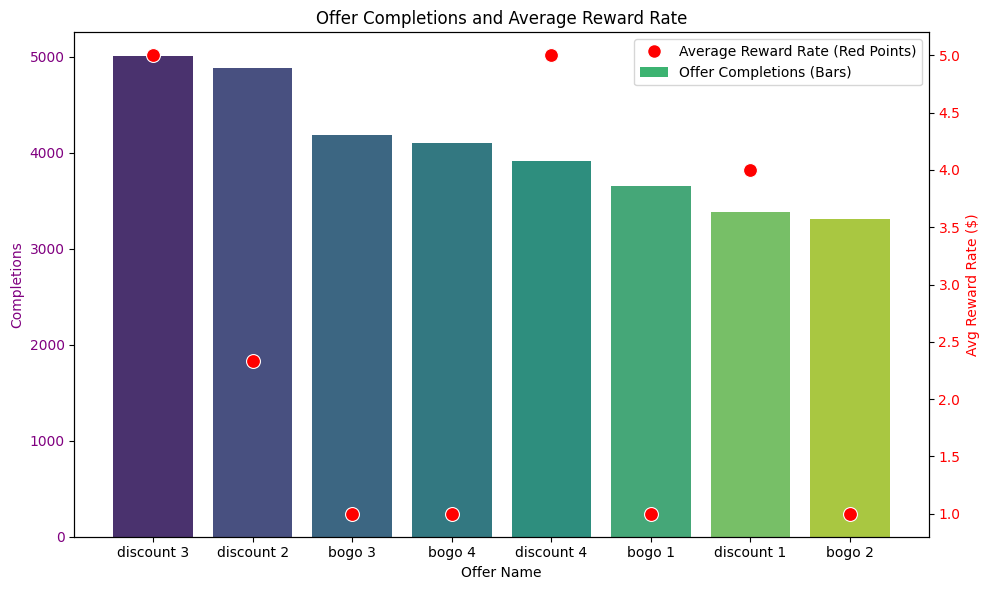

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

# Filter for completed offers
completed_df = df[df['event'] == 'offer completed']

# Group: sum of completions & average reward_rate per offer
summary = completed_df.groupby('offer_name').agg(
    completions=('offer_name', 'count'),
    avg_reward_rate=('reward_rate', 'mean')
).reset_index()

# Sort by completions (descending)
summary = summary.sort_values('completions', ascending=False)

# Plotting
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar plot for completions
bar = sns.barplot(data=summary, x='offer_name', y='completions', ax=ax1, palette='viridis')
ax1.set_ylabel('Completions', color='purple')
ax1.tick_params(axis='y', labelcolor='purple')

# Second y-axis for reward rate
ax2 = ax1.twinx()
scatter = sns.scatterplot(
    data=summary, 
    x='offer_name', 
    y='avg_reward_rate', 
    ax=ax2, 
    color='red', 
    s=100,
    label='Average Reward Rate (Red Points)'
)
ax2.set_ylabel('Avg Reward Rate ($)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Title and labels
plt.title('Offer Completions and Average Reward Rate')
ax1.set_xlabel('Offer Name')
plt.xticks(rotation=45)

# Custom legend
custom_legend = [
    plt.Line2D([0], [0], marker='o', color='w', label='Average Reward Rate (Red Points)',
               markerfacecolor='red', markersize=10),
    plt.Rectangle((0, 0), 1, 1, fc='mediumseagreen', edgecolor='none', label='Offer Completions (Bars)')
]
ax2.legend(handles=custom_legend, loc='upper right')

plt.tight_layout()
plt.show()


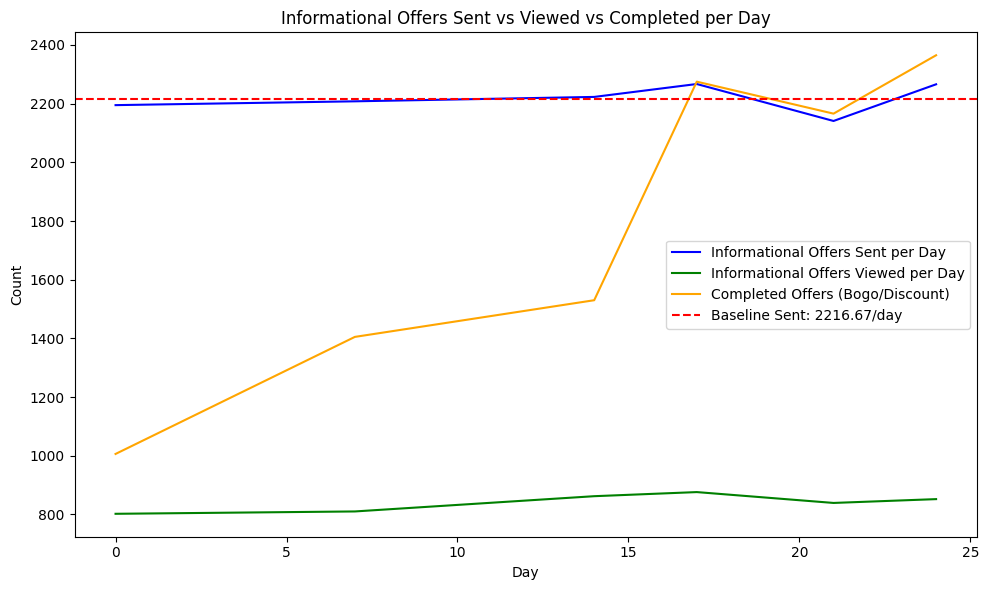

Baseline (average) informational offers sent per day: 2216.67


In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Filter for informational offers sent
inform_sent = df[(df['event'] == 'offer received') & (df['offer_type'] == 'informational')].copy()
inform_sent['day'] = inform_sent['time'] // 24  # assumes time is in hours
info_per_day = inform_sent.groupby('day').size().reset_index(name='informational_sent')

# Filter for informational offers viewed
inform_viewed = df[(df['event'] == 'offer viewed') & (df['offer_type'] == 'informational')].copy()
inform_viewed['day'] = inform_viewed['time'] // 24
viewed_per_day = inform_viewed.groupby('day').size().reset_index(name='informational_viewed')

# Filter for completed offers (discount or bogo)
completed = df[(df['event'] == 'offer completed') & (df['offer_type'].isin(['discount', 'bogo']))].copy()
completed['day'] = completed['time'] // 24
completed_per_day = completed.groupby('day').size().reset_index(name='offers_completed')

# Calculate baseline average informational offers sent per day
baseline_info_sent = info_per_day['informational_sent'].mean()

# Merge all three datasets on 'day'
daily_data = pd.merge(info_per_day, viewed_per_day, on='day', how='left')
daily_data = pd.merge(daily_data, completed_per_day, on='day', how='left')

# Fill missing values with 0
daily_data[['informational_viewed', 'offers_completed']] = daily_data[['informational_viewed', 'offers_completed']].fillna(0)

# Plotting
plt.figure(figsize=(10, 6))
sns.lineplot(x='day', y='informational_sent', data=daily_data, color='blue', label='Informational Offers Sent per Day')
sns.lineplot(x='day', y='informational_viewed', data=daily_data, color='green', label='Informational Offers Viewed per Day')
sns.lineplot(x='day', y='offers_completed', data=daily_data, color='orange', label='Completed Offers (Bogo/Discount)')

# Add horizontal line for the baseline
plt.axhline(baseline_info_sent, color='red', linestyle='--', label=f'Baseline Sent: {baseline_info_sent:.2f}/day')

# Titles and labels
plt.title('Informational Offers Sent vs Viewed vs Completed per Day')
plt.xlabel('Day')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.show()

# Print baseline
print(f"Baseline (average) informational offers sent per day: {baseline_info_sent:.2f}")


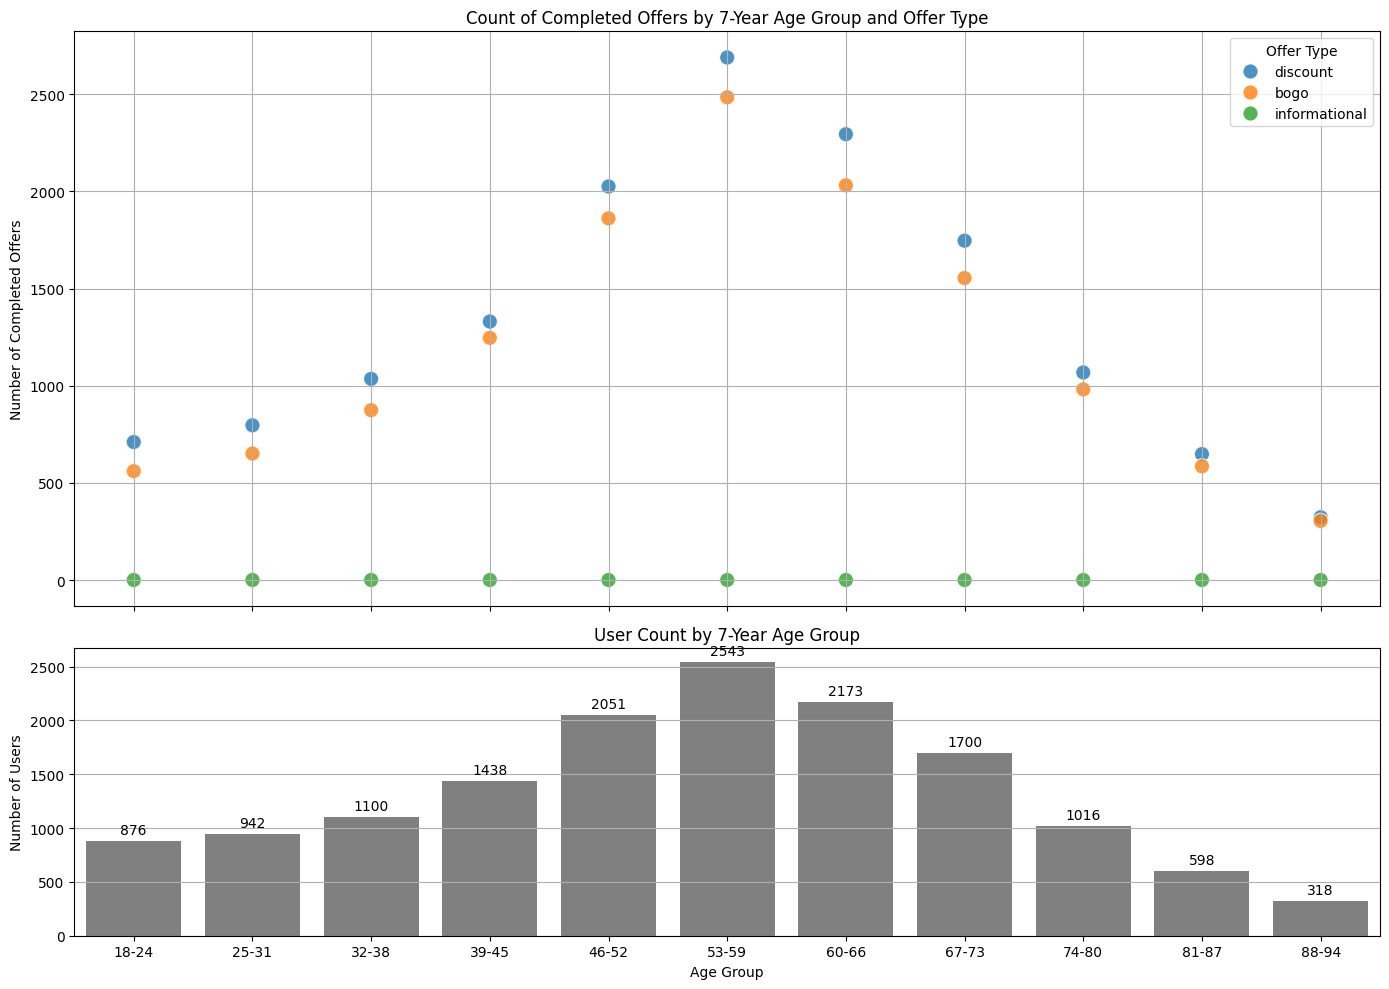

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- Define 7-Year Age Bins ---
age_bins = list(range(18, 101, 7))
age_labels = [f'{i}-{i+6}' for i in age_bins[:-1]]
df['age_group_7yr'] = pd.cut(df['age'], bins=age_bins, labels=age_labels, right=False)

# --- Histogram Data: User Count by Age Bin ---
age_dist = df[['customer_id', 'age_group_7yr']].dropna().drop_duplicates()
age_dist = age_dist.groupby('age_group_7yr', observed=True).size().reset_index(name='count')

# --- Filter and Prepare Offer Completion Data ---
offer_events = df[df['event'].isin(['offer received', 'offer completed'])]
offer_status = offer_events.pivot_table(
    index=['customer_id', 'offer_id', 'offer_type', 'age'],
    columns='event',
    aggfunc='size',
    fill_value=0
).reset_index()

offer_status['completed'] = offer_status['offer completed'] > 0
offer_status['age_group_7yr'] = pd.cut(offer_status['age'], bins=age_bins, labels=age_labels, right=False)

# --- Count Completed Offers by Age Group and Offer Type ---
completed_counts = offer_status[offer_status['completed']].groupby(['age_group_7yr', 'offer_type'], observed=True).size().reset_index(name='completed_count')

# --- Ensure All Age/Offer Combinations Are Represented ---
all_age_groups = df['age_group_7yr'].dropna().unique()
all_offer_types = df['offer_type'].dropna().unique()
age_offer_grid = pd.MultiIndex.from_product(
    [all_age_groups, all_offer_types],
    names=['age_group_7yr', 'offer_type']
).to_frame(index=False)

completed_counts = pd.merge(age_offer_grid, completed_counts, on=['age_group_7yr', 'offer_type'], how='left')
completed_counts['completed_count'] = completed_counts['completed_count'].fillna(0)

# --- Plot: Completed Offers + User Distribution ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

# Scatterplot: Completed Offer Counts
sns.scatterplot(
    data=completed_counts,
    x='age_group_7yr',
    y='completed_count',
    hue='offer_type',
    s=120,
    marker='o',
    alpha=0.8,
    ax=ax1
)
ax1.set_title('Count of Completed Offers by 7-Year Age Group and Offer Type')
ax1.set_ylabel('Number of Completed Offers')
ax1.set_xlabel('')
ax1.grid(True)
ax1.legend(title='Offer Type')

# Histogram: User Count by Age Group
sns.barplot(data=age_dist, x='age_group_7yr', y='count', color='gray', ax=ax2)
ax2.set_title('User Count by 7-Year Age Group')
ax2.set_ylabel('Number of Users')
ax2.set_xlabel('Age Group')
ax2.bar_label(ax2.containers[0], label_type='edge', padding=3)
ax2.grid(axis='y')

plt.tight_layout()
plt.show()


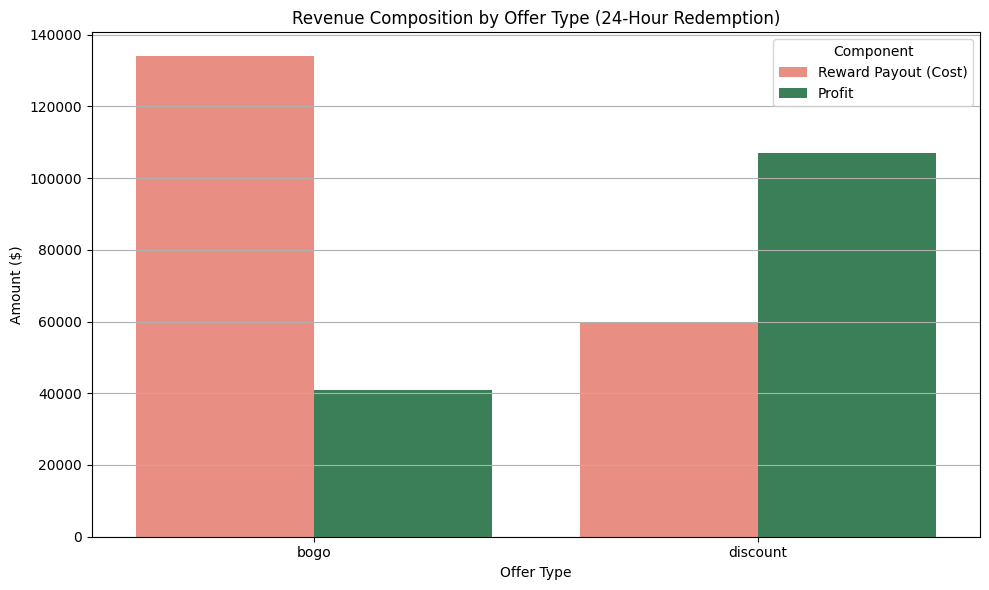

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Clean & Prepare
df.columns = df.columns.str.strip()
df['time'] = pd.to_numeric(df['time'], errors='coerce')
df['transaction_amount'] = pd.to_numeric(df['transaction_amount'], errors='coerce')

# Subsets
offers_received = df[df['event'] == 'offer received'][['customer_id', 'offer_id', 'time']].rename(columns={'time': 'time_received'})
offers_completed = df[df['event'] == 'offer completed'][['customer_id', 'offer_id', 'time', 'offer_type', 'reward']].rename(columns={'time': 'time_completed'})
transactions = df[df['event'] == 'transaction'][['customer_id', 'time', 'transaction_amount']].rename(columns={'time': 'txn_time'})

# Merge offers
offers = pd.merge(offers_completed, offers_received, on=['customer_id', 'offer_id'])
offers = offers[offers['time_completed'] >= offers['time_received']]

# Merge with transactions
offers_expanded = pd.merge(transactions, offers, on='customer_id')
offers_expanded = offers_expanded[
    (offers_expanded['txn_time'] >= offers_expanded['time_received']) &
    (offers_expanded['txn_time'] <= offers_expanded['time_received'] + 24)
]

# Aggregate revenue and rewards
revenue_by_offer = offers_expanded.groupby('offer_type')['transaction_amount'].sum().reset_index(name='revenue')
reward_by_offer = offers.groupby('offer_type')['reward'].sum().reset_index(name='reward_payout')

# Merge + calculate profit
financials = pd.merge(revenue_by_offer, reward_by_offer, on='offer_type', how='left')
financials['profit'] = financials['revenue'] - financials['reward_payout']

# Reshape for stacked bar (melt)
plot_data = financials.melt(id_vars='offer_type', value_vars=['reward_payout', 'profit'],
                            var_name='component', value_name='amount')

# Color mapping
color_map = {
    'reward_payout': 'salmon',
    'profit': 'seagreen'
}

# Plot
plt.figure(figsize=(10, 6))
barplot = sns.barplot(
    data=plot_data,
    x='offer_type',
    y='amount',
    hue='component',
    palette=color_map
)

plt.title('Revenue Composition by Offer Type (24-Hour Redemption)')
plt.xlabel('Offer Type')
plt.ylabel('Amount ($)')
handles, labels = barplot.get_legend_handles_labels()
label_map = {'reward_payout': 'Reward Payout (Cost)', 'profit': 'Profit'}
plt.legend(handles=handles, labels=[label_map[label] for label in labels], title='Component')
plt.tight_layout()
plt.grid(axis='y')
plt.show()


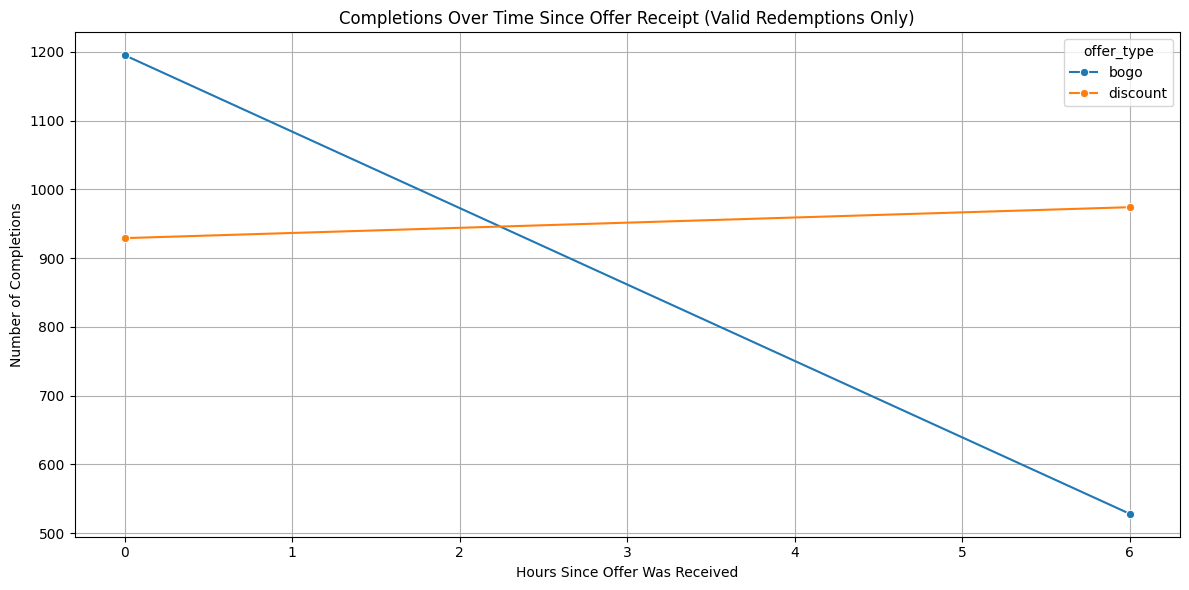

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Clean and Prepare ---
df.columns = df.columns.str.strip()
df['time'] = pd.to_numeric(df['time'], errors='coerce')

# Duration metadata per offer
offer_meta = df[['offer_id', 'duration']].dropna().drop_duplicates()

# Offer received and completed
received = df[df['event'] == 'offer received'][['customer_id', 'offer_id', 'time']].rename(columns={'time': 'time_received'})
completed = df[df['event'] == 'offer completed'][['customer_id', 'offer_id', 'time', 'offer_type']].rename(columns={'time': 'time_completed'})

# Merge and calculate hours since offer was received
merged = pd.merge(completed, received, on=['customer_id', 'offer_id'])
merged = merged[merged['time_completed'] >= merged['time_received']]
merged['hours_since_received'] = merged['time_completed'] - merged['time_received']

# Add duration metadata and filter by allowed window
merged = pd.merge(merged, offer_meta, on='offer_id', how='left')
merged = merged[merged['hours_since_received'] <= merged['duration']]

# Group: count completions by hour and offer type
grouped = merged.groupby(['hours_since_received', 'offer_type']).size().reset_index(name='completions')

# --- Plot ---
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=grouped,
    x='hours_since_received',
    y='completions',
    hue='offer_type',
    marker='o'
)

plt.title('Completions Over Time Since Offer Receipt (Valid Redemptions Only)')
plt.xlabel('Hours Since Offer Was Received')
plt.ylabel('Number of Completions')
plt.grid(True)
plt.tight_layout()
plt.show()
